# Seminar 1 · Part 4: The handwritten digits (MNIST)

We build a **Bernoulli naive Bayes classifier from scratch**: it reads an image of a handwritten digit and tells which digit it is. It is the brain of the demo.

**Plan of this notebook**

1. Load the data
2. Look at the data (EDA)
3. Build the classifier from scratch
4. Train it
5. Evaluate it
6. What the machine thinks each digit looks like
7. Let the machine dream

In [1]:
import gzip
import json
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 0                    # fixed random seed: everyone gets the same "dreams"
DIGITS = list(range(10))    # the classes c = 0, 1, ..., 9

## 1. Load the data

**MNIST**: 70,000 images of handwritten digits, already split into a **training set of 60,000** images and a **test set of 10,000** images. We keep this split. Each image has $28 \times 28 = 784$ pixels, and each pixel has a **gray level** from 0 (background, white) to 255 (ink, black).

The first run downloads 4 files (about 11 MB) into `seminar-1/data/mnist/`. The demo's `train_model.py` uses the same files.

In [2]:
DATA = Path("..") / "data" / "mnist"          # the data folder of Seminar 1
MNIST_URL = "https://raw.githubusercontent.com/fgnt/mnist/master/"


def load_mnist(part):
    '''part = "train" (60,000 images) or "t10k" (10,000 test images). Downloads the files once.
    Returns the gray levels (one row of 784 numbers per image, pixels row by row) and the labels.'''
    arrays = []
    for name, header in [(f"{part}-images-idx3-ubyte.gz", 16), (f"{part}-labels-idx1-ubyte.gz", 8)]:
        path = DATA / name
        if not path.exists():
            DATA.mkdir(parents=True, exist_ok=True)
            print("Downloading", name, "...")
            urllib.request.urlretrieve(MNIST_URL + name, path)
        arrays.append(np.frombuffer(gzip.open(path).read(), np.uint8, offset=header))
    images, labels = arrays
    return images.reshape(-1, 784), labels


gray_train, labels_train = load_mnist("train")
gray_test, labels_test = load_mnist("t10k")
print("Training set:", gray_train.shape, "  (images, pixels)")
print("Test set:    ", gray_test.shape)

Training set: (60000, 784)   (images, pixels)
Test set:     (10000, 784)


## 2. Look at the data (EDA)

### How many images of each digit?

$m$ = the number of training images, $m_c$ = the number of training images of the digit $c$.

m = 60000
          m_c  fraction
digit c                
0        5923     0.099
1        6742     0.112
2        5958     0.099
3        6131     0.102
4        5842     0.097
5        5421     0.090
6        5918     0.099
7        6265     0.104
8        5851     0.098
9        5949     0.099


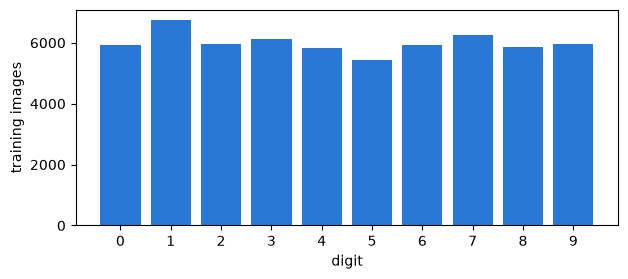

In [3]:
m = len(labels_train)
m_c = np.bincount(labels_train, minlength=10)           # m_c for c = 0, 1, ..., 9

print("m =", m)
print(pd.DataFrame({"m_c": m_c, "fraction": (m_c / m).round(3)}, index=pd.Index(DIGITS, name="digit c")).to_string())

plt.figure(figsize=(7, 2.8))
plt.bar(DIGITS, m_c, color="#2a78d6")
plt.xticks(DIGITS)
plt.xlabel("digit")
plt.ylabel("training images")
plt.show()

Roughly balanced: each digit is between 9.0% and 11.2% of the training set.

### One image = 784 numbers

The first training image, and its gray levels. Python counts from 0: the first image is row 0. Pixel $r$ (numbered 1 to 784, row by row) is column $r - 1$.

The first training image is a 5


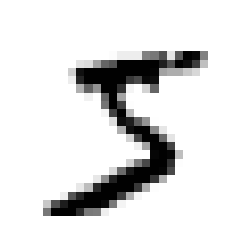

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   

In [4]:
first = gray_train[0]
print("The first training image is a", labels_train[0])

plt.figure(figsize=(3, 3))
plt.imshow(first.reshape(28, 28), cmap="gray_r", vmin=0, vmax=255)
plt.axis("off")
plt.show()

with np.printoptions(linewidth=200):
    print(first.reshape(28, 28))

### Which gray levels?

Count the gray levels of all $60{,}000 \times 784$ pixels of the training set. The vertical axis is logarithmic: each step is 10 times more pixels.

exactly 0 (white):        80.9%
from 1 to 127:            5.9%
from 128 to 255 (dark):   13.2%


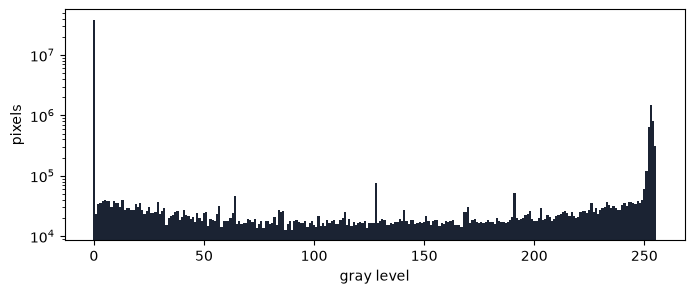

In [5]:
counts = np.bincount(gray_train.ravel(), minlength=256)    # how many pixels have gray level 0, 1, ..., 255
total = counts.sum()
print(f"exactly 0 (white):        {counts[0] / total:.1%}")
print(f"from 1 to 127:            {counts[1:128].sum() / total:.1%}")
print(f"from 128 to 255 (dark):   {counts[128:].sum() / total:.1%}")

plt.figure(figsize=(8, 3))
plt.bar(range(256), counts, width=1, color="#1b2333")
plt.yscale("log")
plt.xlabel("gray level")
plt.ylabel("pixels")
plt.show()

81% of the pixels are exactly white, and most of the dark ones are near 255. A pixel is almost black or white.

### From gray to black and white: binarization

A pixel has **ink** ($u_r = 1$) if its gray level is above 127, the middle of 0–255, and **no ink** ($u_r = 0$) otherwise. Each row of `U_train` is the observed value $u = (u_1, \dots, u_{784})$ of one training image.

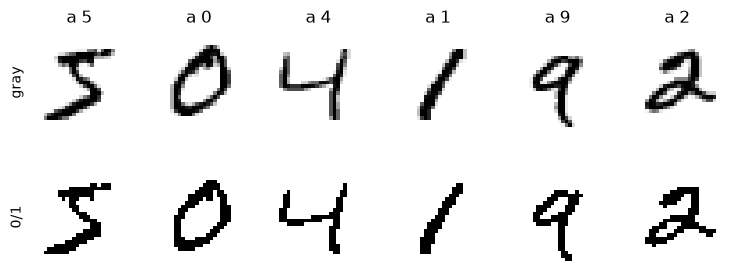

In [6]:
U_train = (gray_train > 127).astype(float)     # 0 or 1
U_test = (gray_test > 127).astype(float)

fig, axes = plt.subplots(2, 6, figsize=(9, 3.2))
for col in range(6):                           # the first 6 training images
    axes[0, col].imshow(gray_train[col].reshape(28, 28), cmap="gray_r", vmin=0, vmax=255)
    axes[1, col].imshow(U_train[col].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    axes[0, col].set_title(f"a {labels_train[col]}")
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].text(-6, 14, "gray", rotation=90, va="center")
axes[1, 0].text(-6, 14, "0/1", rotation=90, va="center")
plt.show()

### Why not the normal distribution?

In the iris part, each feature got a normal distribution. Could we give each **gray level** a normal distribution, for each digit? Count the pixels whose gray level is **the same in all** training images of a digit (variance 0).

In [7]:
for c in DIGITS:
    gray_c = gray_train[labels_train == c]
    print(f"digit {c}: {np.sum(gray_c.var(axis=0) == 0)} of 784 pixels have the same gray level in all {len(gray_c)} images")

digit 0: 219 of 784 pixels have the same gray level in all 5923 images
digit 1: 201 of 784 pixels have the same gray level in all 6742 images
digit 2: 173 of 784 pixels have the same gray level in all 5958 images
digit 3: 199 of 784 pixels have the same gray level in all 6131 images
digit 4: 193 of 784 pixels have the same gray level in all 5842 images
digit 5: 197 of 784 pixels have the same gray level in all 5421 images
digit 6: 224 of 784 pixels have the same gray level in all 5918 images
digit 7: 200 of 784 pixels have the same gray level in all 6265 images
digit 8: 224 of 784 pixels have the same gray level in all 5851 images
digit 9: 233 of 784 pixels have the same gray level in all 5949 images


The PDF of $\mathcal{N}(a, \sigma^2)$ divides by $\sigma^2$: with variance 0 it does not exist. And the gray levels are not bell-shaped at all: almost white or almost black.

After binarization a pixel has only **2 values**, 0 and 1. A distribution on $\{0, 1\}$ is fixed by one number, the probability of 1: it is a **Bernoulli distribution** $\mathrm{Ber}(\theta)$.

| | spam | iris | MNIST |
|---|---|---|---|
| features | word counts $x_w$: 0, 1, 2, … | lengths $z_\ell$ in cm | pixels $u_r$: 0 or 1 |
| given the class | multinomial | normal, for each feature | Bernoulli, for each pixel |

## 3. Build the classifier from scratch

### The model, in one line

Given the digit $\eta = c$, each pixel $\psi_r \sim \mathrm{Ber}(\theta_{c,r})$, and the 784 pixels are conditionally independent (the naive Bayes assumption). So

$$P(\psi = u \mid \eta = c) = \prod_{r=1}^{784} \theta_{c,r}^{\,u_r} (1 - \theta_{c,r})^{1 - u_r}.$$

A pixel **without** ink also counts: it brings the factor $1 - \theta_{c,r}$.

The predicted digit of an image $u$ is the digit with the largest **log score**:

$$\hat{c} = \operatorname*{argmax}_{c} \Big[\log \hat{P}(\eta = c) + \sum_{r=1}^{784} \Big( u_r \log \hat{\theta}_{c,r} + (1 - u_r) \log(1 - \hat{\theta}_{c,r}) \Big)\Big].$$

**Training** is counting. $m_{c,r}$ = the number of training images of the digit $c$ with ink at pixel $r$:

$$\hat{P}(\eta = c) = \frac{m_c}{m}, \qquad \hat{\theta}_{c,r} = \frac{m_{c,r} + 1}{m_c + 2} \quad \text{(Laplace smoothing: 2 outcomes, ink and no ink).}$$

In [8]:
def train_bernoulli_nb(U, labels):
    '''Training = counting.
    U: one row per training image, one column per pixel (0 or 1).  labels: the digit of each image.
    Returns P^(eta = c) (10 numbers) and theta^_{c,r} (a 10 x 784 table: row c, column r - 1).'''
    m = len(labels)                                       # number of training images
    prior = np.zeros(10)
    theta_hat = np.zeros((10, 784))
    for c in DIGITS:
        U_c = U[labels == c]                              # the m_c training images of digit c
        m_c = len(U_c)
        m_cr = U_c.sum(axis=0)                            # m_{c,r}: for each pixel, how many of them have ink there
        prior[c] = m_c / m                                # P^(eta = c) = m_c / m
        theta_hat[c] = (m_cr + 1) / (m_c + 2)             # Laplace smoothing
    return prior, theta_hat


def log_scores(U, prior, theta_hat):
    '''The log score of every digit c, for every image (one row of U per image).
    log P^(eta = c) + sum over r of [ u_r log theta^_{c,r} + (1 - u_r) log(1 - theta^_{c,r}) ]'''
    U = np.atleast_2d(U)
    return np.log(prior) + U @ np.log(theta_hat).T + (1 - U) @ np.log(1 - theta_hat).T


def predict(U, prior, theta_hat):
    '''c^: the digit with the largest log score, for every image.'''
    return log_scores(U, prior, theta_hat).argmax(axis=1)


def posterior(U, prior, theta_hat):
    '''P^(eta = c | psi = u) = e^(log score of c) / sum over c' of e^(log score of c').
    We first subtract the largest log score: this does not change the fractions, and e^(...) does not underflow to 0.'''
    s = log_scores(U, prior, theta_hat)
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

### How many numbers does the model need?

Without the naive Bayes assumption, $P(\psi = u \mid \eta = c)$ needs one number for **every possible image** $u$: there are $2^{784}$ of them. With the assumption: 784 numbers $\theta_{c,r}$ for each digit.

In [9]:
print("2^784 has", len(str(2 ** 784)), "decimal digits:  about 10^236 possible images")
print("training images:", m)
print("naive Bayes:", 10 * 784, "numbers theta_{c,r} + 10 priors =", 10 * 784 + 10)

2^784 has 237 decimal digits:  about 10^236 possible images
training images: 60000
naive Bayes: 7840 numbers theta_{c,r} + 10 priors = 7850


## 4. Train it

The training set: MNIST's 60,000 training images. The test set (10,000 images) stays hidden until step 5.

In [10]:
prior, theta_hat = train_bernoulli_nb(U_train, labels_train)

print("P^(eta = c):", prior.round(3))
print("theta^ is a table of", theta_hat.shape, "numbers, all between", theta_hat.min().round(5), "and", theta_hat.max().round(5))

P^(eta = c): [0.099 0.112 0.099 0.102 0.097 0.09  0.099 0.104 0.098 0.099]
theta^ is a table of (10, 784) numbers, all between 0.00015 and 0.98339


### Check: the demo uses the same model

The demo reads its numbers from `../demo/model.js`, written by `../demo/train_model.py` (rounded to 5 significant digits).

In [11]:
text = Path("../demo/model.js").read_text(encoding="utf-8")
demo = json.loads(text.split("const MODEL = ")[1].strip().rstrip(";"))     # the numbers after "const MODEL = "
print("same priors:", np.allclose(demo["prior"], prior, rtol=1e-4))
print("same theta^:", np.allclose(demo["theta"], theta_hat, rtol=1e-4))

same priors: True
same theta^: True


### Why smoothing? The zero-count problem

Without smoothing, $\hat{\theta}_{c,r} = m_{c,r} / m_c$. For a pixel that has no ink in **any** training image of the digit $c$, this is 0, and $\log 0 = -\infty$.

In [12]:
m_cr = np.array([U_train[labels_train == c].sum(axis=0) for c in DIGITS])    # m_{c,r}: 10 x 784 counts
for c in DIGITS:
    print(f"digit {c}: {np.sum(m_cr[c] == 0)} pixels never have ink in the {m_c[c]} training images")

# A test image with ink at such a pixel gets the probability 0 for that digit
theta_mle = m_cr / m_c[:, None]                                  # without smoothing
dead = (U_test @ (theta_mle == 0).T.astype(float)) > 0           # dead[i, c]: image i has ink where digit c never has
print()
print("Without smoothing:")
print("  test images with probability 0 for their true digit:", np.sum(dead[np.arange(len(labels_test)), labels_test]))
print("  test images with probability 0 for ALL ten digits:   ", np.sum(dead.all(axis=1)), "  <- Bayes' formula gives 0/0")

digit 0: 267 pixels never have ink in the 5923 training images
digit 1: 309 pixels never have ink in the 6742 training images
digit 2: 208 pixels never have ink in the 5958 training images
digit 3: 241 pixels never have ink in the 6131 training images
digit 4: 226 pixels never have ink in the 5842 training images
digit 5: 224 pixels never have ink in the 5421 training images
digit 6: 261 pixels never have ink in the 5918 training images
digit 7: 247 pixels never have ink in the 6265 training images
digit 8: 263 pixels never have ink in the 5851 training images
digit 9: 271 pixels never have ink in the 5949 training images

Without smoothing:
  test images with probability 0 for their true digit: 32
  test images with probability 0 for ALL ten digits:    4   <- Bayes' formula gives 0/0


### Trap question: a blank page

An image with **no ink at all**: $u = (0, 0, \dots, 0)$. What does the classifier say? Guess first, then run the cell.

(The demo shows the prior when nothing is drawn: that is a special rule in the demo's code, not the model.)

In [13]:
blank = np.zeros(784)
p_blank = posterior(blank, prior, theta_hat)[0]
print("predicted digit:", p_blank.argmax(), f"   P^(eta = {p_blank.argmax()} | psi = u) = {p_blank.max():.15f}")

ink = [U_train[labels_train == c].sum(axis=1).mean() for c in DIGITS]
print()
print("average number of ink pixels in a training image of each digit:")
print(pd.Series(np.round(ink, 1), index=pd.Index(DIGITS, name="digit")).to_string())

predicted digit: 1    P^(eta = 1 | psi = u) = 0.999999999999946

average number of ink pixels in a training image of each digit:
digit
0    137.6
1     60.2
2    118.2
3    112.5
4     95.9
5    102.2
6    109.1
7     90.7
8    119.6
9     97.3


**No ink is evidence too.** Each pixel without ink brings the factor $1 - \hat{\theta}_{c,r}$, and the digit 1 has the least ink: a blank page looks most like a 1.

## 5. Evaluate it

The **confusion matrix** counts the test images by predicted digit (rows) and by gold label (columns). With 10 digits it is $10 \times 10$. The correct answers are on the diagonal.

In [14]:
predicted = predict(U_test, prior, theta_hat)

confusion = pd.crosstab(pd.Series(predicted, name="predicted"), pd.Series(labels_test, name="gold"))
print(confusion)

accuracy = np.mean(predicted == labels_test)
print(f"\naccuracy = {np.sum(predicted == labels_test)} / {len(labels_test)} = {accuracy:.4f}")
print(f"'always {np.argmax(m_c)}' (the most frequent training digit): accuracy = {np.mean(labels_test == np.argmax(m_c)):.4f}")

gold         0     1    2    3    4    5    6    7    8    9
predicted                                                   
0          882     0   17    4    2   16   17    2   10   12
1            0  1086   14   17    7   11   14   33   28   13
2            3     6  840   36    4    5   15   17   12    6
3            4     5   32  839    0  106    1    3   68    8
4            1     0   21    1  799   24   14   17   16   64
5           51     9    5   30    2  655   37    0   27    9
6           21     4   28    7   16   18  853    0   10    0
7            1     0   16   13    2    8    0  864    6   29
8           17    25   57   44   12   24    7   25  762   21
9            0     0    2   19  138   25    0   67   35  847

accuracy = 8427 / 10000 = 0.8427
'always 1' (the most frequent training digit): accuracy = 0.1135


### The most common mistakes

In [15]:
mistakes = confusion.to_numpy().copy()
np.fill_diagonal(mistakes, 0)
for cell in np.argsort(mistakes.ravel())[::-1][:5]:    # the 5 largest cells of the table
    pred_c, gold_c = divmod(cell, 10)
    print(f"a {gold_c} called {pred_c}: {mistakes[pred_c, gold_c]} times")

a 4 called 9: 138 times
a 5 called 3: 106 times
a 8 called 3: 68 times
a 7 called 9: 67 times
a 9 called 4: 64 times


Some of the mistakes, with the posterior of the predicted digit:

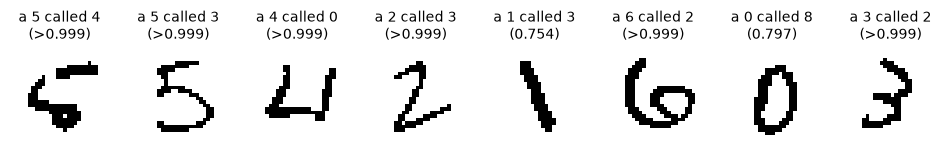

In [16]:
p_test = posterior(U_test, prior, theta_hat)
wrong = np.flatnonzero(predicted != labels_test)

fig, axes = plt.subplots(1, 8, figsize=(12, 2.2))
for ax, i in zip(axes, wrong[:8]):
    ax.imshow(U_test[i].reshape(28, 28), cmap="gray_r")
    best = p_test[i].max()                              # the posterior of the predicted digit
    shown = ">0.999" if best > 0.999 else f"{best:.3f}"      # never round up to 1.000: a posterior below 1 is not 1
    ax.set_title(f"a {labels_test[i]} called {predicted[i]}\n({shown})", fontsize=10)
    ax.axis("off")
plt.show()

### How sure is it?

In [17]:
sure = p_test.max(axis=1)                     # the posterior of the predicted digit
print(f"test images with a posterior above 0.99:             {np.mean(sure > 0.99):.1%}")
print(f"wrong answers:                                       {len(wrong)}")
print(f"wrong answers with a posterior above 0.99:           {np.mean(sure[wrong] > 0.99):.1%}")

test images with a posterior above 0.99:             91.0%
wrong answers:                                       1573
wrong answers with a posterior above 0.99:           67.0%


**Overconfidence.** Two thirds of the wrong answers come with a posterior above 0.99. Naive Bayes can give posteriors very near 0 or 1 because its independence assumption is often false (Murphy, *Probabilistic Machine Learning: An Introduction*, section 9.4.1).

### Compare with scikit-learn

scikit-learn has the same classifier: `BernoulliNB`. With `alpha=1.0` it adds 1 to the two counts (ink, no ink), as we do. Our images are already 0/1, so we switch off its own binarization (`binarize=None`).

In [18]:
from sklearn.naive_bayes import BernoulliNB

sk_model = BernoulliNB(alpha=1.0, binarize=None).fit(U_train, labels_train)
print("same theta^:", np.allclose(np.exp(sk_model.feature_log_prob_), theta_hat))
print("same predictions on the test set:", np.sum(sk_model.predict(U_test) == predicted), "of", len(predicted))

same theta^: True
same predictions on the test set: 10000 of 10000


## 6. What the machine thinks each digit looks like

The 784 numbers $\hat{\theta}_{c,1}, \dots, \hat{\theta}_{c,784}$ of a digit $c$, drawn as a $28 \times 28$ picture: dark where the digit $c$ often has ink.

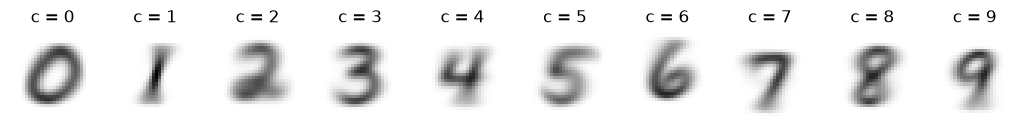

In [19]:
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for c, ax in zip(DIGITS, axes):
    ax.imshow(theta_hat[c].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"c = {c}")
    ax.axis("off")
plt.show()

## 7. Let the machine dream

Naive Bayes is a **generative model**: it describes the joint distribution

$$P(\eta = c, \psi = u) = P(\eta = c)\, P(\psi = u \mid \eta = c),$$

so it can also **generate** images: choose a digit $c$, then draw each pixel on its own, $\psi_r \sim \mathrm{Ber}(\hat{\theta}_{c,r})$, independently of the others.

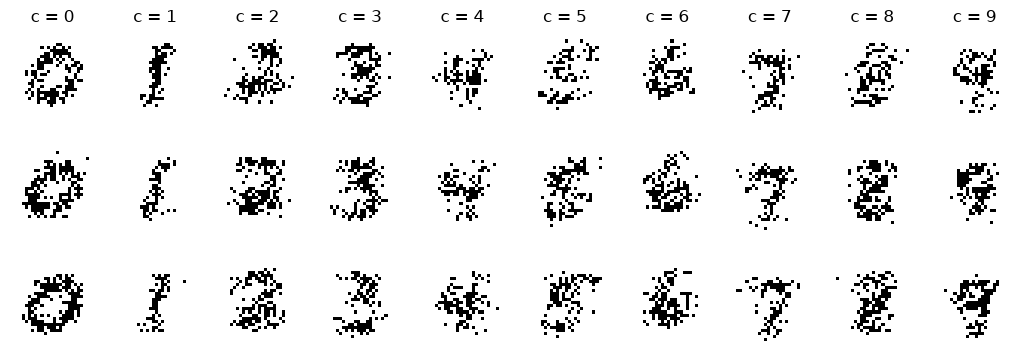

In [20]:
rng = np.random.default_rng(SEED)


def dream(c):
    '''One random image of the digit c: pixel r has ink with probability theta^_{c,r}, independently.'''
    return (rng.random(784) < theta_hat[c]).astype(float)


fig, axes = plt.subplots(3, 10, figsize=(13, 4.2))
for c in DIGITS:
    for row in range(3):
        axes[row, c].imshow(dream(c).reshape(28, 28), cmap="gray_r")
        axes[row, c].axis("off")
    axes[0, c].set_title(f"c = {c}")
plt.show()

The dreams have about as much ink as real digits, but they look like **clouds of dots**, not like strokes of a pen. In a real digit, ink comes in strokes: a pixel next to an ink pixel often has ink too. The model draws every pixel on its own.

### How the independence assumption fails us

Two neighbouring pixels in the middle of the image: pixel $r = 378$ (row 14, column 14) and pixel $r' = 379$ (row 14, column 15). Inside the training images of the digit 5:

In [21]:
r, r_prime = 378, 379                                  # pixels numbered 1 to 784
fives = U_train[labels_train == 5]
ink_r, ink_r_prime = fives[:, r - 1], fives[:, r_prime - 1]    # Python columns r - 1 and r' - 1

print(f"ink at r:                       {ink_r.mean():.3f}")
print(f"ink at r':                      {ink_r_prime.mean():.3f}")
print(f"ink at both:                    {np.mean(ink_r * ink_r_prime):.3f}")
print(f"product (if independent):       {ink_r.mean() * ink_r_prime.mean():.3f}")
print(f"sample correlation coefficient: {np.corrcoef(ink_r, ink_r_prime)[0, 1]:.2f}")

ink at r:                       0.562
ink at r':                      0.494
ink at both:                    0.463
product (if independent):       0.278
sample correlation coefficient: 0.75


If the two pixels were conditionally independent given $\eta = 5$, "ink at both" would be the product, and their correlation would be 0. It is 0.75: the naive Bayes assumption is **false**.

Still, the classifier is right on 84% of the test images.

### Can the machine read its own dreams?

In [22]:
dreams = np.array([dream(c) for c in DIGITS for _ in range(100)])     # 100 dreams of each digit
dream_labels = np.repeat(DIGITS, 100)
print("accuracy on 1,000 dreams:", np.mean(predict(dreams, prior, theta_hat) == dream_labels))

accuracy on 1,000 dreams: 1.0


Yes: its dreams follow exactly its own model, where the pixels **are** independent. Real digits do not.

## Summary

- Pixels are 0 or 1: one **Bernoulli distribution** for each digit and pixel.
- **Bernoulli naive Bayes** = Bayes' formula + the **naive Bayes assumption** + $\mathrm{Ber}(\theta_{c,r})$. Pixels **without** ink count too.
- Training is **counting**, with Laplace smoothing: $\hat{\theta}_{c,r} = (m_{c,r} + 1) / (m_c + 2)$.
- It is a **generative model**: it can dream digits. The dreams show what it misses: neighbouring pixels are not independent.
- 84% of the test digits right, often with too much confidence.

**Read more:** Murphy, *Probabilistic Machine Learning: An Introduction*, section 9.3 "Naive Bayes classifiers" (free PDF: https://probml.github.io/pml-book/book1.html). Its Figure 9.6 is our step 6.